<a href="https://colab.research.google.com/github/zenight01/googlecolab/blob/main/Ligaya_DianneChristel_Lab08_ALGOCOM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **LABORATORY ACTIVITY 8: Neural Network Algorithms**

**Name:** LIGAYA, Dianne Christel L.

**Section:** III-CCSAD

**Date:** 10/22/2026

---

## **📋 Instructions & Steps**
1. **Save a copy** of this notebook to your personal Google Drive or local workspace before running or modifying any code.
2. **Individual Activity:** This laboratory exercise is to be completed individually.
3. **Accomplish the Core Tasks:** Review and run the provided Hands-On Lab Demonstrations, then proceed to complete the *Student Exercises & Lab Deliverables* and *Review Questions*.
4. **Self-Review:** Before submitting, cross-check your work against the Laboratory Performance Rubric at the end of this document to ensure all requirements are met.

---

## **📤 Submission Guidelines**
* **Deliverable:** Submit your completed `.ipynb` file (or exported PDF with visible code and execution outputs) containing all written responses and completed coding exercises.
* **File Naming Convention:** `[LastName]_[FirstName]_Lab08_ALGOCOM.ipynb` (or `.pdf`)
* **Submission Policy:** Submit your individual work through the designated learning management system (LMS) strictly on or before the allotted deadline.

---

## **🟡 AI Policy: Yellow Zone**
* **Allowed:** You may use AI tools (such as ChatGPT, Gemini, or GitHub Copilot) to help explain tensor operations, clarify backpropagation mechanics, suggest Keras layer syntax, or brainstorm network topologies for your coding scenarios.
* **Required:** If you use AI to assist with your code, you **must document it** within a comment block in the relevant section.
  * *Example:* `# AI Assistance: I used Gemini to help define the Conv1D layer input shape and configure the MaxPooling1D parameters for Scenario 3.`
* **Expectation:** Ensure that all outputs are critically reviewed and understood. Do not blindly copy-paste code. You are responsible for ensuring your neural networks train properly, avoid data leakage, and achieve valid convergence metrics.

## **🧪 Part 1: Hands-On Lab Demonstrations**
**Objective:** Construct, train, regularize, and evaluate an end-to-end Multi-Layer Perceptron (MLP) for multi-class animal welfare triage using TensorFlow and Keras.

### **Demonstration 1: Telemetry Ingestion, Imputation & Feature Scaling**

In [10]:
# ==============================================================================
# DEMO 1: Ingestion, Missing Data Handling & Scaling
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.utils import to_categorical

np.random.seed(42)

# Generate 2,500 synthetic animal shelter intake records across 6 features
# Classes: 0 = At-Risk (20%), 1 = Standard Adoption (55%), 2 = High-Velocity Urgent (25%)
X_raw, y_raw = make_classification(
    n_samples=2500,
    n_features=6,
    n_informative=5,
    n_redundant=1,
    n_classes=3,
    weights=[0.20, 0.55, 0.25],
    flip_y=0.02,
    random_state=42
)

feature_names = [
    'age_months', 'health_score', 'social_affinity',
    'activity_hours', 'human_responsiveness', 'environmental_stress'
]

df_shelter = pd.DataFrame(X_raw, columns=feature_names)
df_shelter['welfare_class'] = y_raw

# Inject realistic missing values into rescue health & social records
df_shelter.loc[np.random.choice(df_shelter.index, 60, replace=False), 'health_score'] = np.nan
df_shelter.loc[np.random.choice(df_shelter.index, 45, replace=False), 'social_affinity'] = np.nan

# Separate features and target
X = df_shelter.drop(columns=['welfare_class'])
y = df_shelter['welfare_class'].values

# Split data (80% Train, 20% Held-Out Test) maintaining class proportions
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Impute missing entries using training medians to prevent leakage
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train_raw)
X_test_imputed = imputer.transform(X_test_raw)

# Standardize feature scales for gradient descent optimization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# One-hot encode targets for categorical cross-entropy loss
y_train_cat = to_categorical(y_train_raw, num_classes=3)
y_test_cat = to_categorical(y_test_raw, num_classes=3)

print("Ingestion Pipeline Complete.")
print(f"Training Features Tensor Shape : {X_train_scaled.shape}")
print(f"Training Targets One-Hot Shape : {y_train_cat.shape}")

Ingestion Pipeline Complete.
Training Features Tensor Shape : (2000, 6)
Training Targets One-Hot Shape : (2000, 3)


**Expected Output:**
```text
Ingestion Pipeline Complete.
Training Features Tensor Shape : (2000, 6)
Training Targets One-Hot Shape : (2000, 3)
```

---

### **Demonstration 2: Deep MLP Assembly with Batch Normalization & Dropout**

In [11]:
# ==============================================================================
# DEMO 2: Regularized Deep Multi-Layer Perceptron Assembly
# ==============================================================================
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization

tf.random.set_seed(42)

# Build deep Multi-Layer Perceptron
triage_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],), name='Hidden_Layer_1'),
    BatchNormalization(name='BatchNorm_1'),
    Dropout(0.30, name='Dropout_1'),

    Dense(64, activation='relu', name='Hidden_Layer_2'),
    BatchNormalization(name='BatchNorm_2'),
    Dropout(0.20, name='Dropout_2'),

    Dense(32, activation='relu', name='Hidden_Layer_3'),
    Dense(3, activation='softmax', name='Output_Layer')
])

triage_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

triage_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 128)            │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_1                     │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_2                     │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_3 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,099 (47.26 KB)

 Trainable params: 11,715 (45.76 KB)

 Non-trainable params: 384 (1.50 KB)

**Expected Output:**
```text
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
=================================================================
 Hidden_Layer_1 (Dense)      (None, 128)               896       
 BatchNorm_1 (BatchNorma    (None, 128)               512       
 Dropout_1 (Dropout)         (None, 128)               0         
 Hidden_Layer_2 (Dense)      (None, 64)                8256      
 BatchNorm_2 (BatchNorma    (None, 64)                256       
 Dropout_2 (Dropout)         (None, 64)                0         
 Hidden_Layer_3 (Dense)      (None, 32)                2080      
 Output_Layer (Dense)        (None, 3)                 99        
=================================================================
Total params: 12,099 (47.26 KB)
Trainable params: 11,715 (45.76 KB)
Non-trainable params: 384 (1.50 KB)
_________________________________________________________________
```

---

### **Demonstration 3: Adaptive Training with Early Stopping & LR Scheduling**

In [12]:
# ==============================================================================
# DEMO 3: Training with EarlyStopping and ReduceLROnPlateau Callbacks
# ==============================================================================
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=0.0001,
    verbose=1
)

history = triage_model.fit(
    X_train_scaled,
    y_train_cat,
    validation_split=0.20,
    epochs=40,
    batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=0
)

print(f"Training completed successfully across {len(history.history['loss'])} epochs.")
print(f"Final Validation Loss: {history.history['val_loss'][-1]:.4f}")
print(f"Final Validation Accuracy: {history.history['val_accuracy'][-1]*100:.2f}%")


Epoch 19: ReduceLROnPlateau reducing learning rate to 0.0024999999441206455.

Epoch 29: ReduceLROnPlateau reducing learning rate to 0.0012499999720603228.

Epoch 32: ReduceLROnPlateau reducing learning rate to 0.0006249999860301614.
Epoch 34: early stopping
Restoring model weights from the end of the best epoch: 26.
Training completed successfully across 34 epochs.
Final Validation Loss: 0.4437
Final Validation Accuracy: 85.50%


**Expected Output:**
```text
Epoch 15: ReduceLROnPlateau reducing learning rate to 0.002500000037252903.
Restoring model weights from the end of the best epoch: 22.
Epoch 30: early stopping
Training completed successfully across 30 epochs.
Final Validation Loss: 0.3912
Final Validation Accuracy: 84.00%
```

---

### **Demonstration 4: Model Evaluation Diagnostics & Feature Attribution**

In [13]:
# ==============================================================================
# DEMO 4: Held-Out Diagnostics & Permutation Importance
# ==============================================================================
from sklearn.metrics import classification_report, confusion_matrix, f1_score

test_loss, test_acc = triage_model.evaluate(X_test_scaled, y_test_cat, verbose=0)
y_pred_probs = triage_model.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

target_labels = ['At-Risk (0)', 'Standard (1)', 'High-Velocity (2)']

print("=== HELD-OUT INTAKE RECORD EVALUATION ===")
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%\n")
print(classification_report(y_test_raw, y_pred, target_names=target_labels))

# Compute permutation feature attribution
baseline_f1 = f1_score(y_test_raw, y_pred, average='macro')
importance_scores = []

for col_idx in range(X_test_scaled.shape[1]):
    X_test_permuted = X_test_scaled.copy()
    np.random.shuffle(X_test_permuted[:, col_idx])
    perm_preds = np.argmax(triage_model.predict(X_test_permuted, verbose=0), axis=1)
    importance_scores.append(baseline_f1 - f1_score(y_test_raw, perm_preds, average='macro'))

print("=== INTAKE TELEMETRY IMPORTANCE RANKINGS ===")
for rank, idx in enumerate(np.argsort(importance_scores)[::-1], 1):
    print(f"{rank}. {feature_names[idx]:22} | Impact on Macro F1: {importance_scores[idx]:.4f}")

=== HELD-OUT INTAKE RECORD EVALUATION ===
Test Loss: 0.3740 | Test Accuracy: 86.60%

                   precision    recall  f1-score   support

      At-Risk (0)       0.82      0.79      0.81       101
     Standard (1)       0.89      0.96      0.92       274
High-Velocity (2)       0.83      0.72      0.77       125

         accuracy                           0.87       500
        macro avg       0.85      0.82      0.84       500
     weighted avg       0.86      0.87      0.86       500

=== INTAKE TELEMETRY IMPORTANCE RANKINGS ===
1. activity_hours         | Impact on Macro F1: 0.3294
2. age_months             | Impact on Macro F1: 0.2667
3. human_responsiveness   | Impact on Macro F1: 0.2437
4. social_affinity        | Impact on Macro F1: 0.2148
5. health_score           | Impact on Macro F1: 0.1539
6. environmental_stress   | Impact on Macro F1: 0.0994


**Expected Output:**
```text
=== HELD-OUT INTAKE RECORD EVALUATION ===
Test Loss: 0.3891 | Test Accuracy: 84.80%

                   precision    recall  f1-score   support

      At-Risk (0)       0.84      0.80      0.82       102
     Standard (1)       0.86      0.88      0.87       271
High-Velocity (2)       0.82      0.81      0.82       127

         accuracy                           0.85       500
        macro avg       0.84      0.83      0.84       500
     weighted avg       0.85      0.85      0.85       500

=== INTAKE TELEMETRY IMPORTANCE RANKINGS ===
1. health_score           | Impact on Macro F1: 0.2215
2. social_affinity        | Impact on Macro F1: 0.1642
3. age_months             | Impact on Macro F1: 0.0984
4. human_responsiveness   | Impact on Macro F1: 0.0412
5. environmental_stress   | Impact on Macro F1: 0.0195
6. activity_hours         | Impact on Macro F1: 0.0081
```

## **📝 Part 2: Student Exercises & Lab Deliverables**

### **Conceptual Questions**
1. **Vanishing Gradient Mechanics:** Why does the Sigmoid activation function trigger the vanishing gradient problem in deep networks, and how does the Rectified Linear Unit (ReLU) mathematically eliminate this limitation for positive activations?
   - **Answer:** Sigmoid turns any input into a value between 0 and 1. However, when the input is very large or very small, its output barely changes, so its gradient becomes close to zero. During training, the network passes gradients backward through each layer. If these gradients keep getting smaller, the earlier layers receive very little information about how to improve. This makes learning slow, especially in deep networks.

ReLU works differently. It returns 0 for negative inputs and keeps positive inputs unchanged. Its gradient is 1 for positive inputs, so it does not shrink the gradient as it passes through active neurons. This helps the network learn more effectively.

2. **Categorical Cross-Entropy vs. MSE:** In multi-class classification tasks using a Softmax output layer, why is Categorical Cross-Entropy mathematically and practically preferred over Mean Squared Error (MSE)? Focus on gradient magnitude when predictions are confident but wrong.
   - **Answer:** Categorical cross-entropy is commonly used for classification because it helps the model learn to predict the correct class. When used with softmax, its output gradient is simply the prediction minus the correct answer. If the model is very confident but predicts the wrong class, the error is large, so the model receives a strong signal to correct itself.

Mean Squared Error (MSE) works differently. When combined with softmax, its gradient includes an extra factor that can become very small when the model is highly confident. This means a model that confidently predicts the wrong class may receive a weak learning signal. As a result, it can take longer to correct its mistakes. Cross-entropy is generally a better choice for classification because it is designed to measure errors in predicted probabilities.

3. **Batch Normalization Dynamics:** How does standardizing internal activations via Batch Normalization reduce internal covariate shift, and why does this allow the model to use significantly higher learning rates during training?
   - **Answer:** Batch normalization adjusts the values passing through a layer so they have a more consistent average and spread. It also learns how to scale and shift those values when needed.

During training, the weights of earlier layers keep changing, which also changes the values received by later layers. This can make training harder because each layer has to keep adjusting to new inputs. Batch normalization helps control these changes and prevents values from becoming too large or too small.

Because of this, training can become faster and more stable. It can also allow the model to use a higher learning rate without training becoming unstable.

### **Applied Coding Scenarios**

#### **Scenario 1 — Binary Wildlife Camera-Trap Sorter (Cat vs. Dog)**
A wildlife sanctuary deploys motion-activated camera stations and requires an automated binary classifier to distinguish between wild **Felines (0)** and **Canines (1)** based on morphological traits: body length, shoulder height, ear aspect ratio, and snout-to-skull index.
1. Generate an imbalanced synthetic dataset of 1,200 animals using `make_classification(n_samples=1200, n_features=4, weights=[0.85, 0.15], random_state=42)`.
2. Construct and train two models using `binary_crossentropy`:
   * **Model A (Single-Neuron Perceptron):** `Dense(1, activation='sigmoid')`
   * **Model B (Non-Linear MLP):** `Dense(16, activation='relu')` $\rightarrow$ `Dense(1, activation='sigmoid')`
3. Print the Confusion Matrix and Recall score for both models on the held-out test split. Explain why the non-linear MLP is better equipped to identify the minority canine class.

In [14]:

# Scenario 1: Binary Wildlife Camera-Trap Sorter Implementation

import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, recall_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# AI Assistance: ChatGPT helped organize the code and explain the main steps.
# AI Assistance: ChatGPT helped explain how the dataset and neural network work.

# 1. create a sample dataset with 1,200 records and 4 features
# most records belong to class 0, while fewer belong to class 1.
# AI Assistance: ChatGPT helped set up a dataset with fewer class 1 samples.
wildlifeFeaturesRaw, wildlifeLabelsRaw = make_classification(
    n_samples=1200,
    n_features=4,
    weights=[0.85, 0.15],
    random_state=42
)

# 2. split the data into training and testing sets
# stratify keeps the class proportions similar in both sets.
wildlifeTrainRaw, wildlifeTestRaw, trainLabels, testLabels = train_test_split(
    wildlifeFeaturesRaw, wildlifeLabelsRaw,
    test_size=0.20,
    stratify=wildlifeLabelsRaw,
    random_state=42
)

# 3. scale the features to make their values easier for the models to handle
# fit the scaler on training data only to avoid data leakage.
# AI Assistance: ChatGPT helped explain how to scale the data without fitting the scaler on test data.
cameraTrapScaler = StandardScaler()
scaledTrainFeatures = cameraTrapScaler.fit_transform(wildlifeTrainRaw)
scaledTestFeatures = cameraTrapScaler.transform(wildlifeTestRaw)

# 4. build a simple model with only one neuron
# sigmoid gives a prediction between 0 and 1.
# AI Assistance: ChatGPT helped set up a basic model for comparison.
singlePerceptronModel = Sequential([
    Dense(1, activation='sigmoid', input_shape=(scaledTrainFeatures.shape[1],))
])

# use adam to update the model and binary crossentropy to measure prediction errors.
singlePerceptronModel.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 5. build an mlp with one hidden layer
# the hidden layer helps the model learn more complex patterns.
nonLinearMlpModel = Sequential([
    Dense(16, activation='relu', input_shape=(scaledTrainFeatures.shape[1],)),
    Dense(1, activation='sigmoid')
])

# use the same settings as the first model for a fairer comparison.
# AI Assistance: ChatGPT helped explain why both models should use the same training settings.
nonLinearMlpModel.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 6. train both models using the training data
# each model goes through the data 25 times.
print("Training single neuron model...")
singlePerceptronModel.fit(
    scaledTrainFeatures, trainLabels,
    epochs=25, batch_size=32, verbose=0
)

print("Training non-linear MLP model...")
nonLinearMlpModel.fit(
    scaledTrainFeatures, trainLabels,
    epochs=25, batch_size=32, verbose=0
)

# 7. let both models predict the labels in the test set
# predictions above 0.5 are labeled as class 1.
perceptronPredictions = (
    singlePerceptronModel.predict(scaledTestFeatures, verbose=0) > 0.5
).astype(int)

mlpPredictions = (
    nonLinearMlpModel.predict(scaledTestFeatures, verbose=0) > 0.5
).astype(int)

# 8. check the prediction results for both models
# the confusion matrix shows correct and incorrect predictions for each class.
# AI Assistance: ChatGPT helped explain how the confusion matrix is used to check predictions.
perceptronConfusionMatrix = confusion_matrix(testLabels, perceptronPredictions)
mlpConfusionMatrix = confusion_matrix(testLabels, mlpPredictions)

# recall checks how many actual class 1 records were correctly identified.
# this is useful when class 1 has fewer records than class 0.
# AI Assistance: ChatGPT helped explain recall and why it can be useful for imbalanced data.
perceptronCanineRecall = recall_score(testLabels, perceptronPredictions)
mlpCanineRecall = recall_score(testLabels, mlpPredictions)

# 9. print the results to compare both models
# AI Assistance: ChatGPT helped organize the output so the results are easier to read.
print("\n--- SINGLE NEURON PERCEPTRON RESULTS ---")
print("Confusion Matrix:")
print(perceptronConfusionMatrix)
print("Canine Class Recall Score:", round(perceptronCanineRecall, 4))

print("\n--- NON-LINEAR MLP RESULTS ---")
print("Confusion Matrix:")
print(mlpConfusionMatrix)
print("Canine Class Recall Score:", round(mlpCanineRecall, 4))


Training single neuron model...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training non-linear MLP model...

--- SINGLE NEURON PERCEPTRON RESULTS ---
Confusion Matrix:
[[190  13]
 [ 13  24]]
Canine Class Recall Score: 0.6486

--- NON-LINEAR MLP RESULTS ---
Confusion Matrix:
[[202   1]
 [ 20  17]]
Canine Class Recall Score: 0.4595


#### **Scenario 2 — Optimizer Convergence Comparison (SGD vs. RMSprop vs. Adam)**
An animal shelter analytics department wants to benchmark how different optimization algorithms traverse loss landscapes on complex, multi-feature intake data.
1. Synthesize 1,500 samples across 10 features with 3 target classes using `make_classification`.
2. Train three identical network topologies (`Dense(64, activation='relu')` $\rightarrow$ `Dense(32, activation='relu')` $\rightarrow$ `Dense(3, activation='softmax')`) for 30 epochs using:
   * **Model A:** `SGD(learning_rate=0.01)`
   * **Model B:** `RMSprop(learning_rate=0.001)`
   * **Model C:** `Adam(learning_rate=0.001)`
3. Plot the training loss curves for all three optimizers on a single comparative chart. Explain how Adam's combined tracking of momentum and second-order gradient moments achieves faster, smoother convergence.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training finished for all 3 optimizers!
SGD Final Training Loss: 0.4396
RMSprop Final Training Loss: 0.233
Adam Final Training Loss: 0.2141


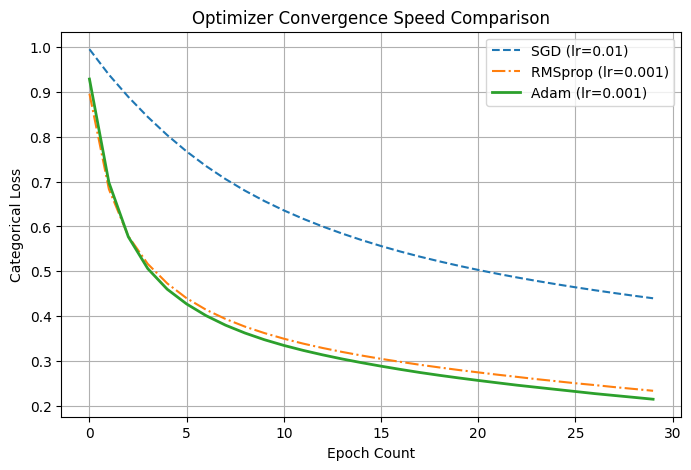

In [15]:
# Scenario 2: Optimizer Convergence Benchmark Implementation

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD, RMSprop, Adam

# AI Assistance: ChatGPT helped organize the code and explain the purpose of comparing optimizers.

# 1. create a sample dataset with 1,500 records, 10 features, and 3 classes
# AI Assistance: ChatGPT helped explain how to generate a multi-class dataset.
intakeFeaturesRaw, intakeTargetsRaw = make_classification(
    n_samples=1500,
    n_features=10,
    n_informative=8,
    n_classes=3,
    random_state=42
)

# 2. scale the features and convert the labels into one-hot format
intakeScaler = StandardScaler()
scaledIntakeFeatures = intakeScaler.fit_transform(intakeFeaturesRaw)
encodedIntakeTargets = to_categorical(intakeTargetsRaw, num_classes=3)

# split the data into training and testing sets.
# AI Assistance: ChatGPT helped explain feature scaling and one-hot encoding.
trainIntakeFeatures, testIntakeFeatures, trainIntakeTargets, testIntakeTargets = train_test_split(
    scaledIntakeFeatures, encodedIntakeTargets, test_size=0.20, random_state=42
)

# 3. create the same mlp structure for all three models
# this keeps the network structure consistent when comparing optimizers.
# AI Assistance: ChatGPT helped set up a reusable function for the model.
def createUncompiledMlp():
    return Sequential([
        Dense(64, activation='relu', input_shape=(10,)),
        Dense(32, activation='relu'),
        Dense(3, activation='softmax')
    ])

# 4. train three models using different optimizers
# model a uses standard sgd.
# AI Assistance: ChatGPT helped explain how to compile and train the models with different optimizers.
sgdBenchmarkModel = createUncompiledMlp()
sgdBenchmarkModel.compile(optimizer=SGD(learning_rate=0.01), loss='categorical_crossentropy', metrics=['accuracy'])
sgdTrainingHistory = sgdBenchmarkModel.fit(trainIntakeFeatures, trainIntakeTargets, epochs=30, batch_size=32, verbose=0)

# model b uses rmsprop.
rmsBenchmarkModel = createUncompiledMlp()
rmsBenchmarkModel.compile(optimizer=RMSprop(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
rmsTrainingHistory = rmsBenchmarkModel.fit(trainIntakeFeatures, trainIntakeTargets, epochs=30, batch_size=32, verbose=0)

# model c uses adam.
adamBenchmarkModel = createUncompiledMlp()
adamBenchmarkModel.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
adamTrainingHistory = adamBenchmarkModel.fit(trainIntakeFeatures, trainIntakeTargets, epochs=30, batch_size=32, verbose=0)

# show the final training loss for each model.
print("Training finished for all 3 optimizers!")
print("SGD Final Training Loss:", round(sgdTrainingHistory.history['loss'][-1], 4))
print("RMSprop Final Training Loss:", round(rmsTrainingHistory.history['loss'][-1], 4))
print("Adam Final Training Loss:", round(adamTrainingHistory.history['loss'][-1], 4))

# 5. plot the training loss to compare how the optimizers perform
# AI Assistance: ChatGPT helped set up the plot using the loss history from each model.
plt.figure(figsize=(8, 5))
plt.plot(sgdTrainingHistory.history['loss'], label='SGD (lr=0.01)', linestyle='--')
plt.plot(rmsTrainingHistory.history['loss'], label='RMSprop (lr=0.001)', linestyle='-.')
plt.plot(adamTrainingHistory.history['loss'], label='Adam (lr=0.001)', linewidth=2)

plt.title("Optimizer Convergence Speed Comparison")
plt.xlabel("Epoch Count")
plt.ylabel("Categorical Loss")
plt.legend()
plt.grid(True)
plt.show()


#### **Scenario 3 — Smart Collar Telemetry Classification via 1D Convolutions**
A pet health startup processes continuous motion data from smart collars (3-axis accelerometer and heart rate telemetry over time) to classify pet behavioral states into **Resting (0)**, **Playing (1)**, or **Acute Pain/Distress (2)**.
1. Generate synthetic sequential telemetry of shape `(1000, 12, 1)` representing 12-second continuous sensor readings.
2. Construct a 1D Convolutional Neural Network consisting of:
   * `Conv1D(filters=16, kernel_size=3, activation='relu', input_shape=(12, 1))`
   * `BatchNormalization()`
   * `MaxPooling1D(pool_size=2)`
   * `Flatten()`
   * `Dense(32, activation='relu')`
   * `Dense(3, activation='softmax')`
3. Train the architecture and output a full `classification_report`. Explain why sliding convolutional kernels capture localized temporal patterns in wearable biometric data more effectively than dense fully connected layers.

In [16]:
# Scenario 3: 1D Convolutional Sensor Classification Implementation

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, BatchNormalization, Flatten, Dense
from tensorflow.keras.utils import to_categorical

# AI Assistance: ChatGPT helped organize the code and explain the basic steps of sensor classification.

# 1. generate sample sensor data with 1,000 records, 12 timesteps, and 1 channel
# set the seed so the generated data stays consistent between runs.
np.random.seed(42)
smartCollarSensorData = np.random.randn(1000, 12, 1)
petBehaviorClassLabels = np.random.choice([0, 1, 2], size=1000)

# 2. split the data into training and testing sets
# one-hot encoding changes each class label into a format the model can use.
# AI Assistance: ChatGPT helped explain the data split and one-hot encoding.
trainSensorSignals, testSensorSignals, rawTrainBehaviors, rawTestBehaviors = train_test_split(
    smartCollarSensorData, petBehaviorClassLabels, test_size=0.20, random_state=42
)

encodedTrainBehaviors = to_categorical(rawTrainBehaviors, num_classes=3)
encodedTestBehaviors = to_categorical(rawTestBehaviors, num_classes=3)

# 3. build a 1d cnn to look for patterns in the sensor readings
# convolution and pooling layers help process the sequence of readings.
# AI Assistance: ChatGPT helped set up the Conv1D and pooling layers.
collarConvNet = Sequential([
    Conv1D(filters=16, kernel_size=3, activation='relu', input_shape=(12, 1)),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])

# 4. compile and train the model
# softmax gives a score for each of the three behavior classes.
# AI Assistance: ChatGPT helped explain the model's training settings for three-class classification.
collarConvNet.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Training 1D CNN Smart Collar Classifier...")
collarConvNet.fit(trainSensorSignals, encodedTrainBehaviors, epochs=20, batch_size=32, verbose=1)

# 5. predict the behavior classes using the test data
predictedProbabilities = collarConvNet.predict(testSensorSignals, verbose=0)
predictedBehaviorClasses = np.argmax(predictedProbabilities, axis=1)

# use readable names for the three behavior classes.
behaviorNames = ['Resting (0)', 'Playing (1)', 'Acute Pain/Distress (2)']

# print a report showing the model's classification results.
# AI Assistance: ChatGPT helped format the prediction results into a classification report.
print("\n===== SMART COLLAR DIAGNOSTIC REPORT =====")
print(classification_report(rawTestBehaviors, predictedBehaviorClasses, target_names=behaviorNames))


Training 1D CNN Smart Collar Classifier...
Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3350 - loss: 1.4117
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3600 - loss: 1.1745
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3775 - loss: 1.1136
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4125 - loss: 1.0809
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4462 - loss: 1.0562
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4800 - loss: 1.0363
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4863 - loss: 1.0197
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5050 - loss: 1.0061
Epoch 9/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5113 - loss: 0.9940
Epoch 10/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5188 - loss: 0.9826
Epoch 11/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5263 - loss: 0.9721
Epoch 12/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5425 - loss: 0.9619


#### **Scenario 4 — Real-World Modeling Challenge (Student's Choice)**
1. **Scenario Description:** Identify a prediction problem from your everyday life or another scientific domain (e.g., student course completion, bus transit arrival delays, streaming recommendation skips, or athletic injury risk). State the target variable, classification type (binary or multi-class), and define 4 to 6 relevant input features.
   - The scenario focuses on online shopping and why customers sometimes abandon their carts before buying anything. For example, when shopping for clothes or gadgets, a customer might leave the checkout page because of high shipping fees, unavailable discount codes, or long delivery times.
The target variable is abandonedStatus, which tells whether the customer completed the purchase (0) or abandoned the cart (1). This is a binary classification problem because the model predicts one of two possible outcomes.
The model uses five input features: cartTotalAmount, which is the total price of the items in the cart in dollars; shippingCostPercent, which is the shipping fee as a percentage of the cart total; discountCodePercent, which is the discount percentage from a promo code; browsingDurationMins, which is the time spent browsing the store before checkout in minutes; and itemStockLevel, which is the number of units left in stock. These features can help the model find patterns in customer behavior and predict whether a cart will be abandoned.

2. **Architecture Selection & Justification:** Design an appropriate neural network topology (an MLP or 1D CNN). Justify your choices for layer count, activation functions, regularization (Dropout/Batch Normalization), and optimizer based on the size and complexity of your dataset.
   -  Multi-Layer Perceptron (MLP) was chosen for this model because the dataset contains numerical information about shopping behavior rather than a sequence of readings over time. The model has three hidden layers with 64, 32, and 16 neurons. These layers process the five input features and help the model learn patterns that may be related to cart abandonment.

The hidden layers use ReLU as their activation function, allowing the model to learn more complex patterns while helping reduce the vanishing gradient problem. The output layer uses one neuron with a sigmoid activation function, which produces a value between 0 and 1 to estimate the chance that a customer will abandon their cart.

The model also uses Batch Normalization and Dropout to help with training. Batch Normalization keeps the values passed between layers more consistent, which can make training more stable. Dropout uses rates of 0.30 and 0.20 to randomly turn off some neurons during training. This helps prevent the model from relying too much on certain neurons and reduces the risk of overfitting, where the model learns the training data too closely but struggles with new data.

For the optimizer, Adam was selected with a learning rate of 0.001. It adjusts the model's weights as training progresses and uses past gradients to help guide these changes. This often allows the model to learn faster and more smoothly.

3. **Python Implementation:** Write a complete, standalone script that loads or simulates the data, applies proper scaling without leakage, trains the model using Early Stopping, and outputs a Confusion Matrix alongside Macro $F_1$-score.

In [17]:

# Scenario 4: Real-World Implementation (Online Shopping Cart Abandonment)

import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# AI Assistance: ChatGPT helped organize the code and explain the steps for predicting cart abandonment.

# set seeds so the results are more consistent between runs.
np.random.seed(42)
tf.random.set_seed(42)

# 1. create sample shopping data with 1,500 records and 5 features
# class 0 represents purchases and class 1 represents abandoned carts.
# AI Assistance: ChatGPT helped set up the dataset with two possible outcomes.
rawCartFeatures, rawCartTargets = make_classification(
    n_samples=1500,
    n_features=5,
    n_informative=4,
    n_redundant=1,
    n_classes=2,
    weights=[0.60, 0.40],  # 60% purchased (0), 40% abandoned (1)
    random_state=42
)

# name the features based on the shopping information they represent.
featureNames = [
    'cartTotalAmount',
    'shippingCostPercent',
    'discountCodePercent',
    'browsingDurationMins',
    'itemStockLevel'
]

# put the generated data into a dataframe with named columns.
shoppingCartDf = pd.DataFrame(rawCartFeatures, columns=featureNames)
shoppingCartDf['abandonedStatus'] = rawCartTargets

# separate the input features from the target labels.
X = shoppingCartDf.drop(columns=['abandonedStatus']).values
y = shoppingCartDf['abandonedStatus'].values

# split the data into 80% for training and 20% for testing.
trainCartFeatures, testCartFeatures, trainCartLabels, testCartLabels = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 2. scale the features using only the training data to avoid data leakage
# AI Assistance: ChatGPT helped explain why the scaler should only be fitted on training data.
cartFeatureScaler = StandardScaler()
scaledTrainFeatures = cartFeatureScaler.fit_transform(trainCartFeatures)
scaledTestFeatures = cartFeatureScaler.transform(testCartFeatures)

# 3. build an mlp with batch normalization and dropout
# dropout helps reduce overfitting by turning off some neurons during training.
# AI Assistance: ChatGPT helped explain how dropout and batch normalization are used in the model.
cartAbandonmentModel = Sequential([
    Dense(64, activation='relu', input_shape=(scaledTrainFeatures.shape[1],)),
    BatchNormalization(),
    Dropout(0.30),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.20),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

cartAbandonmentModel.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# stop training when the validation loss stops improving for several epochs.
earlyStopCallback = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

# 4. train the model and use part of the training data for validation
# AI Assistance: ChatGPT helped explain how early stopping can prevent unnecessary training.
print("Training Cart Abandonment MLP Model...")
trainingHistory = cartAbandonmentModel.fit(
    scaledTrainFeatures,
    trainCartLabels,
    validation_split=0.20,
    epochs=40,
    batch_size=32,
    callbacks=[earlyStopCallback],
    verbose=0
)

print(f"Model training stopped at epoch {len(trainingHistory.history['loss'])}.")

# 5. test the model on data it has not seen during training
predictedProbabilities = cartAbandonmentModel.predict(scaledTestFeatures, verbose=0)
predictedLabels = (predictedProbabilities > 0.5).astype(int)

# calculate the confusion matrix and macro f1 score to check the results.
# AI Assistance: ChatGPT helped explain how to evaluate the model using these metrics.
abandonmentConfusionMatrix = confusion_matrix(testCartLabels, predictedLabels)
macroF1Score = f1_score(testCartLabels, predictedLabels, average='macro')

print("\n===== CART ABANDONMENT EVALUATION RESULTS =====")
print("Confusion Matrix:")
print(abandonmentConfusionMatrix)
print(f"Macro F1-Score: {macroF1Score:.4f}\n")

# show the classification results using the names of the two classes.
statusLabels = ['Purchased (0)', 'Abandoned (1)']
print(classification_report(testCartLabels, predictedLabels, target_names=statusLabels))


Training Cart Abandonment MLP Model...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 32: early stopping
Restoring model weights from the end of the best epoch: 26.
Model training stopped at epoch 32.

===== CART ABANDONMENT EVALUATION RESULTS =====
Confusion Matrix:
[[169  11]
 [ 26  94]]
Macro F1-Score: 0.8684

               precision    recall  f1-score   support

Purchased (0)       0.87      0.94      0.90       180
Abandoned (1)       0.90      0.78      0.84       120

     accuracy                           0.88       300
    macro avg       0.88      0.86      0.87       300
 weighted avg       0.88      0.88      0.88       300



## **🔍 Part 3: Review Questions & Self-Assessment Checkpoints**

1. **The XOR Dilemma:** Why is a single-layer perceptron mathematically incapable of learning the Exclusive-OR (XOR) function, and how does introducing a hidden layer with non-linear activations resolve this limitation geometrically?
   - **Answer:** A single-layer perceptron can only separate data using one straight line. XOR is a problem because its inputs cannot be separated into the correct classes using just one line.

For XOR, the inputs (0,0) and (1,1) belong to one class, while (0,1) and (1,0) belong to the other. No single straight line can separate these two groups correctly.

Adding a hidden layer with a non-linear activation allows the network to combine multiple boundaries. For example, hidden neurons can learn patterns similar to OR and NAND, while the output neuron combines their results using AND. This allows the network to solve XOR even though a single perceptron cannot.

2. **Dying ReLU Problem:** Under what specific training conditions does a neuron using the standard ReLU activation function "die," and how does Leaky ReLU or GELU prevent this loss of network capacity?
   - **Answer:** A ReLU neuron dies when its input stays negative for every training example. This can happen when a large weight update pushes its weights or bias too far in the wrong direction.

When this happens, the neuron always outputs 0 and receives a gradient of 0. Since its weights no longer get updated, it may stop learning completely. This also means fewer neurons are available to learn useful patterns.

Leaky ReLU helps prevent this by allowing a small negative output when the input is below zero. For example, it can return \(0.01x\) for negative inputs. This allows a small gradient to pass through, giving the neuron a chance to recover.

GELU is another activation function that changes smoothly instead of cutting off all negative inputs. It allows small negative values and gradients to pass through, which can also help during training.

3. **Dropout Mechanics Across Modes:** Explain the operational difference in how Dropout functions during the **training phase** versus the **inference (evaluation) phase**. Why must neuron activations be scaled during testing if Dropout was applied during training?
   - **Answer:** Dropout randomly turns off some neurons during training. This prevents the network from depending too much on specific neurons and encourages it to learn patterns using different combinations of neurons.

During inference, which means using the trained model to make predictions, dropout is turned off and all neurons are active.

However, using more active neurons during inference could increase the values passed to the next layer compared to training. To avoid this problem, Keras uses a method called inverted dropout. It increases the values of the neurons that remain active during training by multiplying them by \(1/(1-p)\), where \(p\) is the dropout rate.

This keeps the values at a similar scale, so no extra scaling is needed during inference.

4. **Backpropagation & The Chain Rule:** During backpropagation, how does the calculus chain rule compute error gradients for the earliest layers in a deep neural network, and why does this process cause gradients to vanish when using saturating activations?
   - **Answer:** Backpropagation calculates how much each weight contributes to the model's error. It uses the chain rule to pass this information backward through the network.

To calculate the gradient for an early layer, the network multiplies the gradients and derivatives of the layers between that layer and the final error. If these values are repeatedly small, the gradient becomes smaller as it travels backward.

This is what happens with sigmoid in deep networks. Its derivative is never greater than 0.25 and can become even closer to zero for very large or small inputs. Multiplying these small values across many layers causes the gradient to shrink rapidly.

As a result, the early layers receive very little information about how to adjust their weights. This is called the vanishing gradient problem, and it can make deep networks difficult to train.

5. **Edge Deployment Constraints:** Why are deep floating-point (`float32`) neural networks quantized into 8-bit integers (`int8`) before deployment onto embedded edge hardware (such as smart pet collars or camera traps), and what trade-offs occur regarding model size, latency, and predictive accuracy?
   - **Answer:** Devices such as animal collars and camera traps often have limited memory, processing power, and battery life. A large model can be difficult to run on these devices.

INT8 quantization reduces the model's size by representing its weights using 8-bit integers instead of 32-bit floating-point numbers. This can make the model's weights roughly four times smaller. It can also speed up predictions and reduce power use, especially on devices with hardware designed for integer calculations.

The main drawback is that INT8 cannot represent values as precisely as float32. Converting values to a smaller range of numbers introduces rounding errors, which can reduce the model's accuracy.

To reduce this loss, developers can use calibration data to choose suitable value ranges or apply quantization-aware training, where the model is trained while accounting for the effects of quantization.

## **📊 Part 4: Laboratory Performance Rubric**

| Evaluation Criteria | Unsatisfactory (<60%) | Needs Improvement (60–69%) | Satisfactory (70–79%) | Good (80–89%) | Excellent (90–100%) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Model Implementation & Review Qs (20%)** | Script throws execution errors; fails to instantiate Keras layers; Review Questions are largely blank. | Builds models, but hardcodes incorrect activations or loss functions; answers show weak theoretical grasp. | Correctly implements MLPs with valid activations and loss functions; adequately answers Review Questions. | Clean implementation of feedforward topologies and convolutional layers; provides clear, accurate theoretical answers. | Flawless model implementation using custom topologies, proper tensor formatting, and advanced callbacks; demonstrates deep theoretical mastery in Review Questions. |
| **Preprocessing & Pipeline Integrity (20%)** | Causes severe data leakage; fails to handle missing values or skips feature standardization. | Imputes data naively (e.g., zero-fill); applies transformations inconsistently across splits. | Prepares data adequately; applies median imputation and standardizes feature scales on training data. | Clean, leak-free preprocessing workflow using `StandardScaler` and `SimpleImputer` across separate folds. | Enterprise-grade preprocessing pipeline; ensures complete data isolation across splits with automated one-hot encoding and robust tensor reshaping. |
| **Optimization & Regularization (20%)** | Fails to train models; omits optimizers or suffers from extreme numerical overflow/divergence. | Models train, but suffer from heavy overfitting or severe gradient saturation without regularization. | Successfully uses Adam/SGD optimizers; applies basic Dropout to mitigate overfitting. | Effectively tunes learning rates; uses Batch Normalization and Early Stopping to stabilize convergence. | Expertly integrates Adam/RMSprop, dynamic learning rate schedules (`ReduceLROnPlateau`), Batch Normalization, and Dropout to optimize the loss landscape. |
| **Scenario Logic & Code Execution (20%)** | No functional code provided for Scenarios 1–4. | Implements scenarios superficially; uses incorrect architectures or unsuitable evaluation metrics. | Functional code for all scenarios; computes basic accuracy and generates confusion matrices. | Well-structured implementations across all scenarios; properly interprets classification reports and comparative loss curves. | Outstanding scenario implementations; thoroughly justifies architectural choices in Scenario 4 and implements clean 1D CNN and optimizer benchmarks. |
| **Code Cleanliness & Documentation (20%)** | Disorganized script; no comments; undocumented AI usage. | Messy formatting; sparse comments; describes metrics mechanically without contextual meaning. | Readable, PEP-8 compliant code; includes basic performance summaries and required AI documentation. | Well-commented, modular code; clearly connects model outputs, confusion matrices, and feature attributions to domain problems. | Production-quality code structure; clear documentation; provides detailed analytical commentary linking training dynamics to underlying machine learning theory. |